# 📊 Credit Risk Transition Matrix — Demo

Este notebook demonstra todas as funcionalidades da biblioteca usando dados fictícios de uma carteira de crédito simulada com 500 contratos ao longo de 24 meses.

## 1. Setup e Geração de Dados Fictícios

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

from credit_risk_transition_matrix import (
    TransitionMatrixLearner,
    cumulative_pd,
    marginal_pd,
    pd_term_structure,
    survival_curve,
    cure_rates,
    absorbing_analysis
)

print(f"Library loaded successfully")

Library loaded successfully


In [2]:
def generate_portfolio(n_contracts=500, n_months=24, seed=42):
    """
    Gera uma carteira fictícia de crédito com comportamento realista.
    
    Simula contratos que podem:
    - Permanecer em dia (alta probabilidade)
    - Piorar (migrar para faixas de atraso maiores)
    - Curar (migrar de volta para faixas melhores)
    - Entrar em default (360+ dias)
    """
    np.random.seed(seed)
    
    dates = pd.date_range('2022-01-31', periods=n_months, freq='ME')
    segments = ['Pessoa Física', 'Pessoa Jurídica', 'Consignado']
    segment_probs = [0.50, 0.30, 0.20]
    
    # Probabilidades de transição por segmento (simplificadas)
    # [prob_melhora, prob_piora, prob_cura_from_default]
    segment_risk = {
        'Consignado':      {'worsen': 0.03, 'cure': 0.08, 'ead_range': (1000, 20000)},
        'Pessoa Física':   {'worsen': 0.08, 'cure': 0.05, 'ead_range': (5000, 100000)},
        'Pessoa Jurídica': {'worsen': 0.12, 'cure': 0.04, 'ead_range': (50000, 500000)}
    }
    
    bucket_steps = [0, 15, 30, 60, 90, 120, 180, 240, 360]
    
    records = []
    for i in range(n_contracts):
        contract_id = f"CTR-{i+1:04d}"
        segment = np.random.choice(segments, p=segment_probs)
        risk = segment_risk[segment]
        
        # EAD do contrato
        ead = np.random.uniform(*risk['ead_range'])
        
        # Estado inicial: maioria começa em dia
        current_idx = np.random.choice(range(len(bucket_steps)), p=[
            0.70, 0.10, 0.05, 0.04, 0.03, 0.02, 0.02, 0.02, 0.02
        ])
        
        for date in dates:
            days_past_due = bucket_steps[current_idx]
            
            records.append({
                'id_contrato': contract_id,
                'data_ref': date,
                'dias_atraso': days_past_due,
                'segmento': segment,
                'ead': round(ead, 2)
            })
            
            # Simular transição
            rnd = np.random.random()
            if rnd < risk['worsen']:
                # Piora: avança 1-2 faixas
                step = np.random.choice([1, 2], p=[0.7, 0.3])
                current_idx = min(current_idx + step, len(bucket_steps) - 1)
            elif rnd < risk['worsen'] + risk['cure'] and current_idx > 0:
                # Cura: volta 1-2 faixas
                step = np.random.choice([1, 2], p=[0.8, 0.2])
                current_idx = max(current_idx - step, 0)
    
    df = pd.DataFrame(records)
    df['data_ref'] = pd.to_datetime(df['data_ref'])
    return df

# Gerar dados
df = generate_portfolio(n_contracts=500, n_months=24)

print(f"Shape: {df.shape}")
print(f"Contratos: {df['id_contrato'].nunique()}")
print(f"Período: {df['data_ref'].min().strftime('%Y-%m')} a {df['data_ref'].max().strftime('%Y-%m')}")
print(f"Segmentos: {df['segmento'].unique().tolist()}")
print(f"\nDistribuição de atraso:")
print(df['dias_atraso'].value_counts().sort_index())

df.head(10)

Shape: (12000, 5)
Contratos: 500
Período: 2022-01 a 2023-12
Segmentos: ['Pessoa Física', 'Consignado', 'Pessoa Jurídica']

Distribuição de atraso:
dias_atraso
0      4697
15     2091
30     1622
60     1123
90      696
120     593
180     451
240     283
360     444
Name: count, dtype: int64


,id_contrato,data_ref,dias_atraso,segmento,ead
0,CTR-0001,2022-01-31,15,Pessoa Física,95317.86
1,CTR-0001,2022-02-28,15,Pessoa Física,95317.86
2,CTR-0001,2022-03-31,15,Pessoa Física,95317.86
3,CTR-0001,2022-04-30,15,Pessoa Física,95317.86
4,CTR-0001,2022-05-31,60,Pessoa Física,95317.86
5,CTR-0001,2022-06-30,60,Pessoa Física,95317.86
6,CTR-0001,2022-07-31,60,Pessoa Física,95317.86
7,CTR-0001,2022-08-31,120,Pessoa Física,95317.86
8,CTR-0001,2022-09-30,120,Pessoa Física,95317.86
9,CTR-0001,2022-10-31,120,Pessoa Física,95317.86


## 2. Treinamento da Matriz de Transição

In [3]:
# Separar treino e teste (80/20 temporal)
cutoff_date = df['data_ref'].quantile(0.8)
df_train = df[df['data_ref'] <= cutoff_date].copy()
df_test = df[df['data_ref'] > cutoff_date].copy()

print(f"Treino: {len(df_train)} observações ({df_train['data_ref'].min().strftime('%Y-%m')} a {df_train['data_ref'].max().strftime('%Y-%m')})")
print(f"Teste:  {len(df_test)} observações ({df_test['data_ref'].min().strftime('%Y-%m')} a {df_test['data_ref'].max().strftime('%Y-%m')})")

Treino: 10000 observações (2022-01 a 2023-08)
Teste:  2000 observações (2023-09 a 2023-12)


In [4]:
# Inicializar e treinar
learner = TransitionMatrixLearner(
    buckets=[0, 15, 30, 60, 90, 120, 180, 240, 360],
    time_horizon=12,
    min_observations=10
)

learner.fit(
    df_train,
    id_col='id_contrato',
    time_col='data_ref',
    bucket_col='dias_atraso',
    segment_col='segmento'
)

print(learner)
print(f"\nBuckets: {learner.bucket_labels_}")
print(f"Segmentos: {list(learner.segmented_matrices_.keys())}")

TransitionMatrixLearner(buckets=9, time_horizon=12, segments=3, status=fitted)

Buckets: ['0-14', '15-29', '30-59', '60-89', '90-119', '120-179', '180-239', '240-359', '360+']
Segmentos: ['Pessoa Física', 'Consignado', 'Pessoa Jurídica']


## 3. Matriz de Transição Global

In [5]:
# Visualizar a matriz numérica
matrix = learner.transition_matrix_
print("Matriz de Transição Global (probabilidades):")
print()
print(matrix.round(4).to_string())
print()
print("Soma das linhas (deve ser ~1.0):")
print(matrix.sum(axis=1).round(6))

Matriz de Transição Global (probabilidades):

           0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
0-14     0.9245  0.0521  0.0234  0.0000  0.0000   0.0000   0.0000   0.0000  0.0000
15-29    0.0574  0.8503  0.0615  0.0308  0.0000   0.0000   0.0000   0.0000  0.0000
30-59    0.0050  0.0426  0.8654  0.0619  0.0251   0.0000   0.0000   0.0000  0.0000
60-89    0.0000  0.0181  0.0314  0.8565  0.0663   0.0277   0.0000   0.0000  0.0000
90-119   0.0000  0.0000  0.0151  0.0344  0.8516   0.0667   0.0323   0.0000  0.0000
120-179  0.0000  0.0000  0.0000  0.0098  0.0367   0.8729   0.0660   0.0147  0.0000
180-239  0.0000  0.0000  0.0000  0.0000  0.0031   0.0583   0.8497   0.0583  0.0307
240-359  0.0000  0.0000  0.0000  0.0000  0.0000   0.0152   0.0457   0.8579  0.0812
360+     0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0094   0.0344  0.9562

Soma das linhas (deve ser ~1.0):
0-14       1.0
15-29      1.0
30-59      1.0
60-89      1.0
90-119     1.0
120-179    1.0


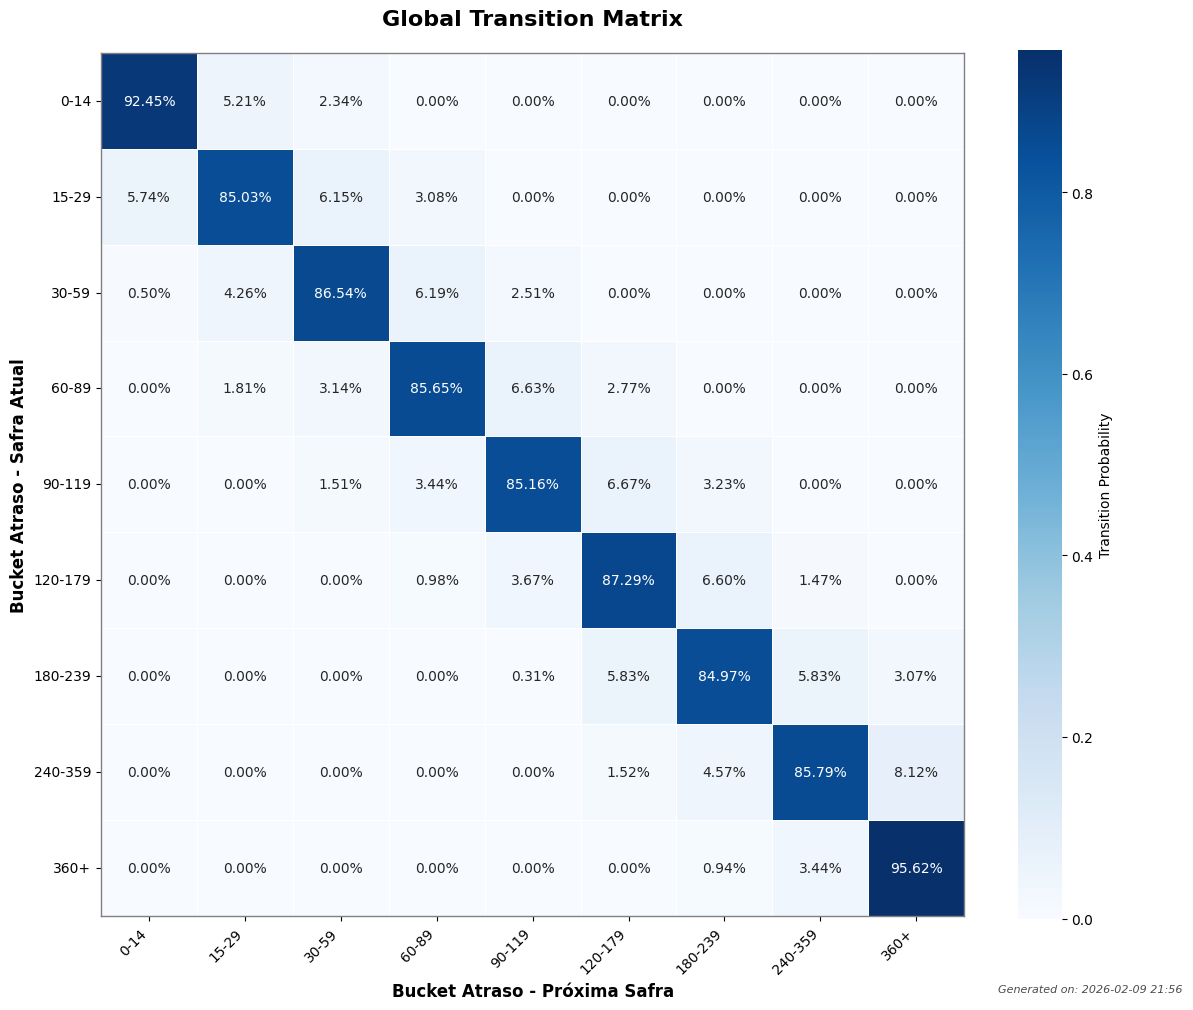

In [6]:
# Heatmap da matriz global
figures = learner.plot_heatmaps(modes=['global'])
# A figura é exibida automaticamente em Jupyter

## 4. Análise Segmentada

In [7]:
# Matrizes segmentadas
matrices = learner.transform(modes=['global', 'segmented'])

for segment_name, seg_matrix in matrices.get('segmented', {}).items():
    print(f"\n{'='*60}")
    print(f"Segmento: {segment_name}")
    print(f"{'='*60}")
    print(seg_matrix.round(4).to_string())
    print()


Segmento: Pessoa Física
           0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
0-14     0.9174  0.0590  0.0237  0.0000  0.0000   0.0000   0.0000   0.0000  0.0000
15-29    0.0569  0.8561  0.0600  0.0269  0.0000   0.0000   0.0000   0.0000  0.0000
30-59    0.0092  0.0382  0.8718  0.0489  0.0321   0.0000   0.0000   0.0000  0.0000
60-89    0.0000  0.0202  0.0277  0.8615  0.0554   0.0353   0.0000   0.0000  0.0000
90-119   0.0000  0.0000  0.0234  0.0234  0.8304   0.0819   0.0409   0.0000  0.0000
120-179  0.0000  0.0000  0.0000  0.0088  0.0263   0.8860   0.0746   0.0044  0.0000
180-239  0.0000  0.0000  0.0000  0.0000  0.0000   0.0541   0.8595   0.0541  0.0324
240-359  0.0000  0.0000  0.0000  0.0000  0.0000   0.0175   0.0263   0.8684  0.0877
360+     0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0068   0.0411  0.9521


Segmento: Consignado
           0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
0-14     0.9684  0.0191  0.0124  0.0000

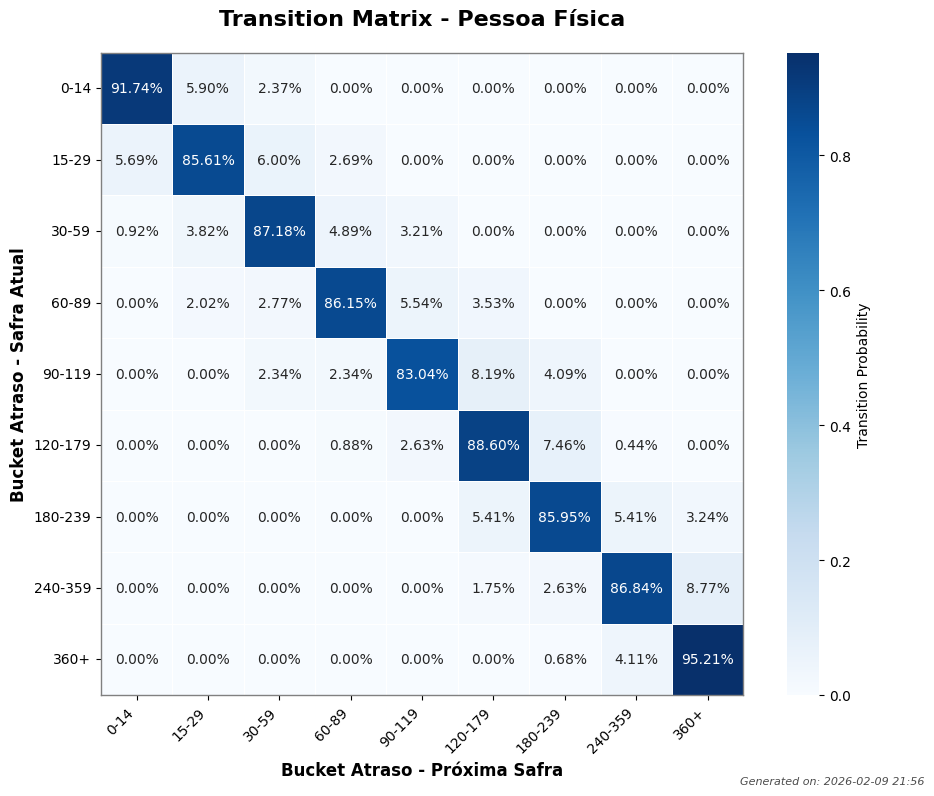

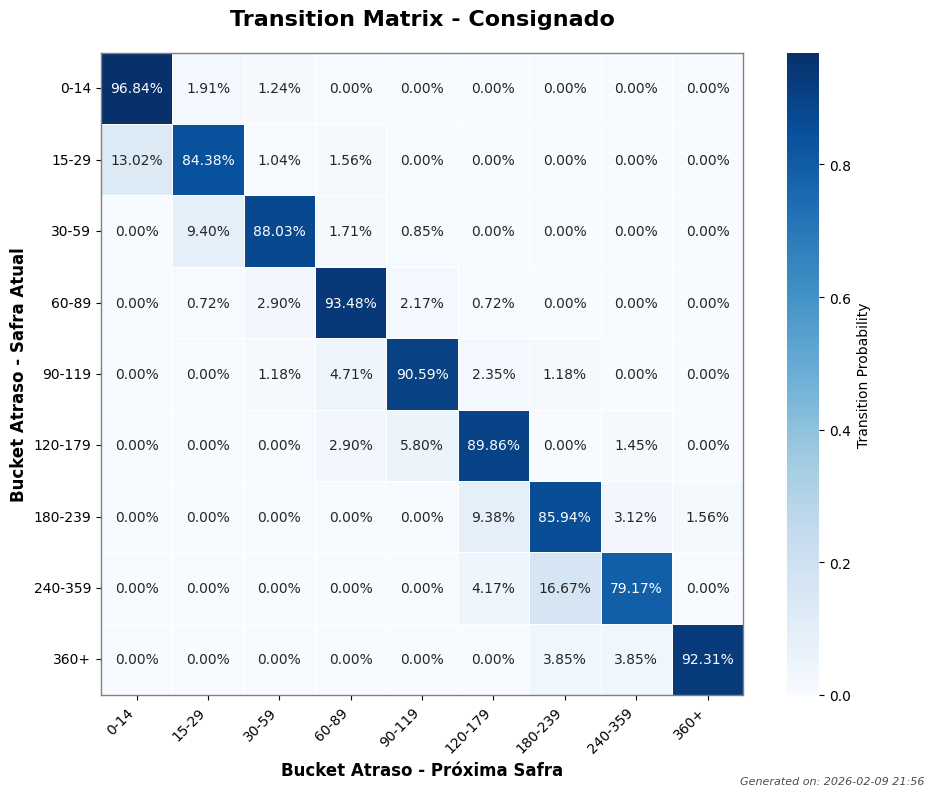

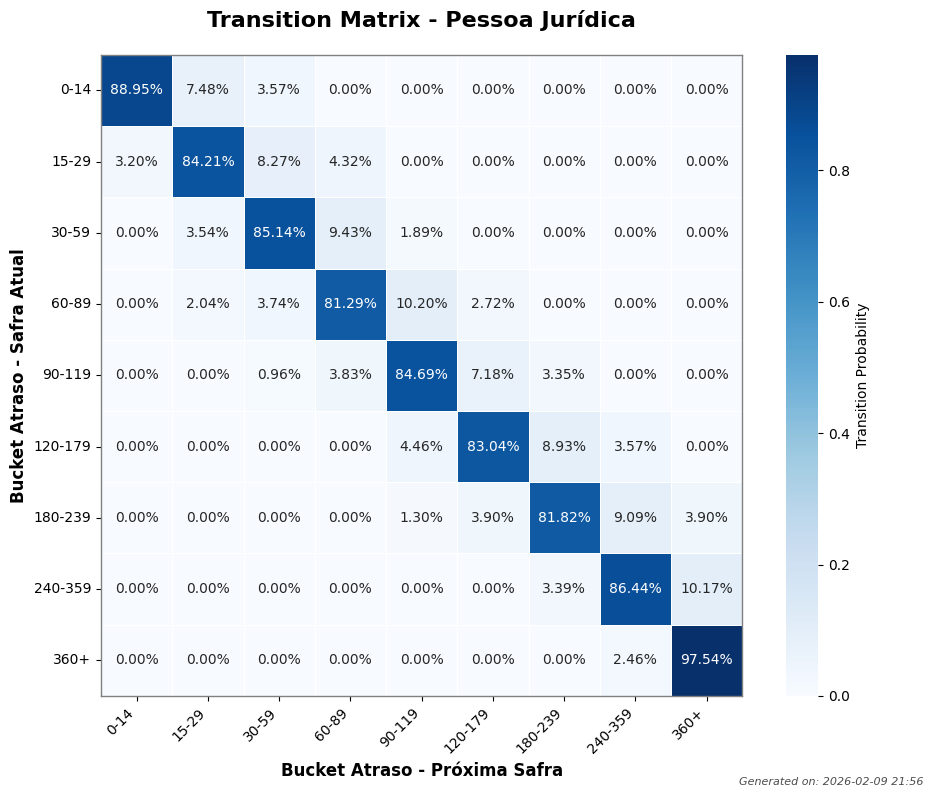

In [8]:
# Heatmaps segmentados
figures = learner.plot_heatmaps(modes=['segmented'])

## 5. PD Engine — Análises de Probabilidade de Default

### 5.1 PD Cumulativa e Marginal

In [9]:
# PD Cumulativa: probabilidade de atingir default até o período t
cpd = cumulative_pd(learner.transition_matrix_, n_periods=12)

print("PD Cumulativa (12 meses):")
print(cpd.round(4).to_string())

PD Cumulativa (12 meses):
      0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
1   0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0307   0.0812  0.9562
2   0.0000  0.0000  0.0000  0.0000  0.0010   0.0032   0.0601   0.1487  0.9175
3   0.0000  0.0000  0.0000  0.0002  0.0030   0.0090   0.0881   0.2049  0.8830
4   0.0000  0.0000  0.0001  0.0006  0.0060   0.0168   0.1144   0.2517  0.8523
5   0.0000  0.0000  0.0003  0.0014  0.0099   0.0261   0.1390   0.2906  0.8247
6   0.0000  0.0001  0.0006  0.0026  0.0147   0.0366   0.1619   0.3230  0.7999
7   0.0000  0.0002  0.0010  0.0042  0.0203   0.0480   0.1831   0.3500  0.7775
8   0.0001  0.0004  0.0017  0.0063  0.0266   0.0599   0.2027   0.3725  0.7573
9   0.0001  0.0006  0.0025  0.0089  0.0334   0.0721   0.2208   0.3913  0.7388
10  0.0002  0.0009  0.0036  0.0119  0.0407   0.0846   0.2373   0.4068  0.7220
11  0.0003  0.0014  0.0049  0.0154  0.0484   0.0971   0.2526   0.4198  0.7067
12  0.0005  0.0020  0.0065  0.0193  0.

In [10]:
# PD Marginal: probabilidade de default no período t dado que sobreviveu até t-1
mpd = marginal_pd(learner.transition_matrix_, n_periods=12)

print("PD Marginal (12 meses):")
print(mpd.round(4).to_string())

PD Marginal (12 meses):
      0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
1   0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0307   0.0812  0.9562
2   0.0000  0.0000  0.0000  0.0000  0.0010   0.0032   0.0295   0.0675 -0.0388
3   0.0000  0.0000  0.0000  0.0002  0.0020   0.0058   0.0280   0.0562 -0.0345
4   0.0000  0.0000  0.0001  0.0004  0.0030   0.0078   0.0263   0.0468 -0.0308
5   0.0000  0.0000  0.0002  0.0008  0.0039   0.0093   0.0246   0.0389 -0.0276
6   0.0000  0.0001  0.0003  0.0012  0.0048   0.0105   0.0229   0.0324 -0.0248
7   0.0000  0.0001  0.0005  0.0016  0.0056   0.0113   0.0212   0.0270 -0.0224
8   0.0000  0.0002  0.0006  0.0021  0.0062   0.0119   0.0196   0.0225 -0.0203
9   0.0001  0.0002  0.0008  0.0026  0.0068   0.0123   0.0180   0.0187 -0.0184
10  0.0001  0.0003  0.0011  0.0030  0.0073   0.0125   0.0166   0.0156 -0.0168
11  0.0001  0.0005  0.0013  0.0035  0.0077   0.0125   0.0152   0.0129 -0.0154
12  0.0002  0.0006  0.0016  0.0039  0.00

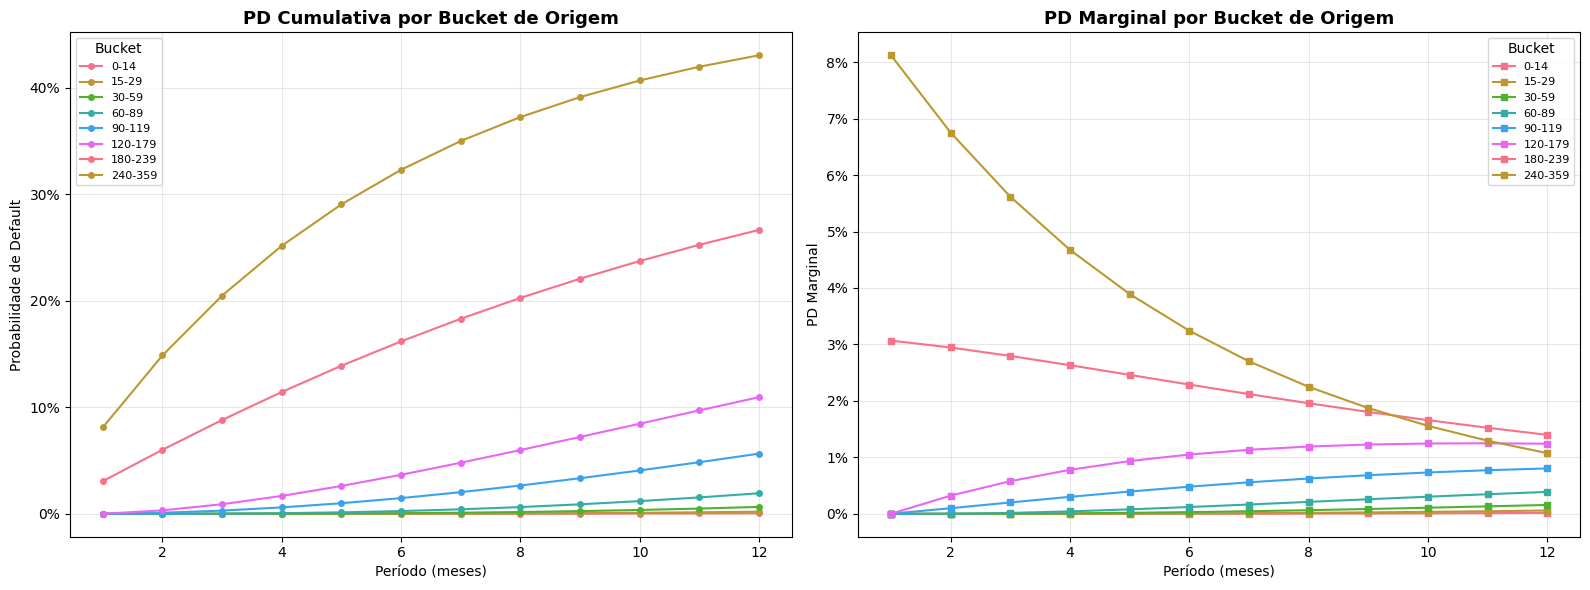

In [11]:
# Gráfico de PD cumulativa por bucket
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Selecionar os buckets mais relevantes
buckets_to_plot = [b for b in cpd.columns if b != '360+']

# PD Cumulativa
for bucket in buckets_to_plot:
    axes[0].plot(cpd.index, cpd[bucket], marker='o', markersize=4, label=bucket)
axes[0].set_title('PD Cumulativa por Bucket de Origem', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Período (meses)')
axes[0].set_ylabel('Probabilidade de Default')
axes[0].legend(title='Bucket', fontsize=8)
axes[0].grid(alpha=0.3)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

# PD Marginal
for bucket in buckets_to_plot:
    axes[1].plot(mpd.index, mpd[bucket], marker='s', markersize=4, label=bucket)
axes[1].set_title('PD Marginal por Bucket de Origem', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Período (meses)')
axes[1].set_ylabel('PD Marginal')
axes[1].legend(title='Bucket', fontsize=8)
axes[1].grid(alpha=0.3)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
plt.show()

### 5.2 Curva de Sobrevivência

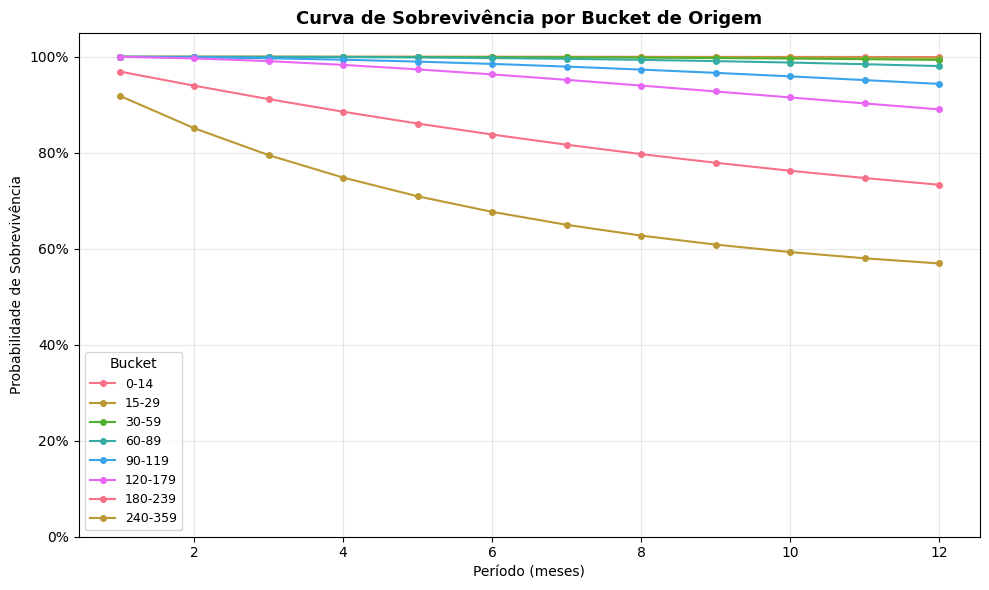

In [12]:
surv = survival_curve(learner.transition_matrix_, n_periods=12)

fig, ax = plt.subplots(figsize=(10, 6))

for bucket in buckets_to_plot:
    ax.plot(surv.index, surv[bucket], marker='o', markersize=4, label=bucket)

ax.set_title('Curva de Sobrevivência por Bucket de Origem', fontsize=13, fontweight='bold')
ax.set_xlabel('Período (meses)')
ax.set_ylabel('Probabilidade de Sobrevivência')
ax.legend(title='Bucket', fontsize=9)
ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

### 5.3 PD Term Structure Completa

In [13]:
# Term structure via convenience method
ts = learner.get_pd_term_structure(n_periods=12)

# Mostrar para o bucket 0-14 (contratos em dia)
first_bucket = learner.bucket_labels_[0]
print(f"PD Term Structure — Bucket '{first_bucket}':")
print()
ts_display = ts[first_bucket].copy()
ts_display.columns = ['PD Cumulativa', 'PD Marginal', 'Sobrevivência']
print(ts_display.round(4).to_string())

PD Term Structure — Bucket '0-14':

        PD Cumulativa  PD Marginal  Sobrevivência
period                                           
1              0.0000       0.0000         1.0000
2              0.0000       0.0000         1.0000
3              0.0000       0.0000         1.0000
4              0.0000       0.0000         1.0000
5              0.0000       0.0000         1.0000
6              0.0000       0.0000         1.0000
7              0.0000       0.0000         1.0000
8              0.0001       0.0000         0.9999
9              0.0001       0.0001         0.9999
10             0.0002       0.0001         0.9998
11             0.0003       0.0001         0.9997
12             0.0005       0.0002         0.9995


### 5.4 Cure Rates

In [14]:
# Cure rates: probabilidade de migrar para faixas melhores
cures = learner.get_cure_rates()

# Mostrar totais de cura por bucket
total_cures = cures[cures['to_bucket'] == '_TOTAL_CURE_'].copy()
total_cures = total_cures[['from_bucket', 'cure_probability']].reset_index(drop=True)
total_cures.columns = ['Faixa de Atraso', 'Taxa de Cura']

print("Taxa de Cura por Faixa de Atraso:")
print("(Probabilidade de migrar para uma faixa melhor no próximo período)")
print()
for _, row in total_cures.iterrows():
    bar = '█' * int(row['Taxa de Cura'] * 50)
    print(f"  {row['Faixa de Atraso']:>10s}  {row['Taxa de Cura']:6.2%}  {bar}")

print()
print("\nDetalhe completo de curas:")
detail = cures[cures['to_bucket'] != '_TOTAL_CURE_'].copy()
detail.columns = ['De', 'Para', 'Probabilidade']
print(detail.to_string(index=False))

Taxa de Cura por Faixa de Atraso:
(Probabilidade de migrar para uma faixa melhor no próximo período)

       15-29   5.74%  ██
       30-59   4.77%  ██
       60-89   4.95%  ██
      90-119   4.95%  ██
     120-179   4.65%  ██
     180-239   6.13%  ███
     240-359   6.09%  ███
        360+   4.38%  ██


Detalhe completo de curas:
     De    Para  Probabilidade
  15-29    0-14       0.057396
  30-59    0-14       0.005017
  30-59   15-29       0.042642
  60-89   15-29       0.018094
  60-89   30-59       0.031363
 90-119   30-59       0.015054
 90-119   60-89       0.034409
120-179   60-89       0.009780
120-179  90-119       0.036675
180-239  90-119       0.003067
180-239 120-179       0.058282
240-359 120-179       0.015228
240-359 180-239       0.045685
   360+ 180-239       0.009375
   360+ 240-359       0.034375


### 5.5 Absorbing State Analysis

In [15]:
# Absorbing analysis: tempo esperado até default
analysis = learner.get_absorbing_analysis()

print("Tempo Esperado até Default (em períodos mensais):")
print("="*50)
expected = analysis['expected_steps'].sort_values(ascending=False)
for bucket, steps in expected.items():
    bar = '▓' * int(min(steps, 50))
    print(f"  {bucket:>10s}  {steps:6.1f} meses  {bar}")

print()
print("\nProbabilidade de Absorção:")
print(analysis['absorption_probabilities'].round(4).to_string())

Tempo Esperado até Default (em períodos mensais):
        0-14   128.7 meses  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
       15-29   119.1 meses  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
       30-59   107.1 meses  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
       60-89    93.1 meses  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
      90-119    76.9 meses  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
     120-179    62.9 meses  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
     180-239    43.4 meses  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
     240-359    27.7 meses  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓


Probabilidade de Absorção:
         360+
0-14      1.0
15-29     1.0
30-59     1.0
60-89     1.0
90-119    1.0
120-179   1.0
180-239   1.0
240-359   1.0


## 6. Predição de Estados Futuros

In [16]:
# Predição: distribuição futura a partir de um bucket
print("Predição de distribuição de estados (a partir de cada bucket):")
print()

for n_periods in [1, 3, 6, 12]:
    print(f"\n--- Horizonte: {n_periods} meses ---")
    for bucket in learner.bucket_labels_[:4]:  # Primeiros 4 buckets
        future = learner.predict_transitions(bucket, n_periods=n_periods)
        # Encontrar bucket mais provável
        max_idx = future.index(max(future))
        most_likely = learner.bucket_labels_[max_idx]
        print(f"  {bucket:>10s} → {most_likely} ({max(future):.1%})")

Predição de distribuição de estados (a partir de cada bucket):


--- Horizonte: 1 meses ---
        0-14 → 0-14 (92.5%)
       15-29 → 15-29 (85.0%)
       30-59 → 30-59 (86.5%)
       60-89 → 60-89 (85.6%)

--- Horizonte: 3 meses ---
        0-14 → 0-14 (79.9%)
       15-29 → 15-29 (63.1%)
       30-59 → 30-59 (66.1%)
       60-89 → 60-89 (64.1%)

--- Horizonte: 6 meses ---
        0-14 → 0-14 (65.6%)
       15-29 → 15-29 (43.3%)
       30-59 → 30-59 (46.6%)
       60-89 → 60-89 (44.0%)

--- Horizonte: 12 meses ---
        0-14 → 0-14 (47.3%)
       15-29 → 15-29 (25.9%)
       30-59 → 30-59 (27.7%)
       60-89 → 60-89 (25.1%)


In [17]:
# PD por bucket (método legado do learner)
pd_results = learner.calculate_pd(time_horizon=12)

print("PD por Bucket (horizonte 12 meses):")
print(f"Default definido como: {pd_results['default_buckets']}")
print()
for bucket, pd_val in pd_results['pd_by_bucket'].items():
    bar = '█' * int(pd_val * 50)
    print(f"  {bucket:>10s}  {pd_val:6.2%}  {bar}")

PD por Bucket (horizonte 12 meses):
Default definido como: ['360+']

        0-14   0.05%  
       15-29   0.20%  
       30-59   0.65%  
       60-89   1.93%  
      90-119   5.65%  ██
     120-179  10.95%  █████
     180-239  26.66%  █████████████
     240-359  43.05%  █████████████████████
        360+  69.25%  ██████████████████████████████████


## 7. Validação do Modelo

In [18]:
# Validar usando dados out-of-time
results = learner.validate_model(
    test_data=df_test,
    metrics=['accuracy', 'stability', 'coverage']
)

print("Métricas de Validação:")
print("="*40)
print(f"  Accuracy:  {results['accuracy']:.2%}")
print(f"  Stability: {results['stability']:.4f}")
print(f"  Coverage:  {results['coverage']:.2%}")
print()
print("Interpretação:")
print(f"  • Accuracy: % de transições onde o bucket mais provável foi correto")
print(f"  • Stability: média da diagonal principal (dominância diagonal)")
print(f"  • Coverage: % de células da matriz que são não-zero")

Métricas de Validação:
  Accuracy:  89.00%
  Stability: 0.8761
  Coverage:  48.15%

Interpretação:
  • Accuracy: % de transições onde o bucket mais provável foi correto
  • Stability: média da diagonal principal (dominância diagonal)
  • Coverage: % de células da matriz que são não-zero


## 8. Matriz Ponderada por EAD

In [19]:
# Treinar com ponderação por EAD
learner_weighted = TransitionMatrixLearner(
    buckets=[0, 15, 30, 60, 90, 120, 180, 240, 360],
    min_observations=10
)

learner_weighted.fit(
    df_train,
    id_col='id_contrato',
    time_col='data_ref',
    bucket_col='dias_atraso',
    weight_col='ead'  # Ponderação por exposição
)

print("Matriz de Transição Ponderada por EAD:")
print(learner_weighted.transition_matrix_.round(4).to_string())
print()

# Comparar com a matriz baseada em contagem
diff = learner_weighted.transition_matrix_ - learner.transition_matrix_
print("\nDiferença (Ponderada - Contagem):")
print(diff.round(4).to_string())

Matriz de Transição Ponderada por EAD:
           0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
0-14     0.9002  0.0700  0.0298  0.0000  0.0000   0.0000   0.0000   0.0000  0.0000
15-29    0.0411  0.8440  0.0784  0.0366  0.0000   0.0000   0.0000   0.0000  0.0000
30-59    0.0022  0.0384  0.8429  0.0935  0.0231   0.0000   0.0000   0.0000  0.0000
60-89    0.0000  0.0165  0.0366  0.8259  0.0854   0.0356   0.0000   0.0000  0.0000
90-119   0.0000  0.0000  0.0110  0.0414  0.8458   0.0737   0.0281   0.0000  0.0000
120-179  0.0000  0.0000  0.0000  0.0027  0.0515   0.8520   0.0682   0.0256  0.0000
180-239  0.0000  0.0000  0.0000  0.0000  0.0174   0.0585   0.8001   0.0823  0.0418
240-359  0.0000  0.0000  0.0000  0.0000  0.0000   0.0040   0.0325   0.8928  0.0708
360+     0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0020   0.0300  0.9680


Diferença (Ponderada - Contagem):
           0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
0-14    -0.0

## 9. Serialização (Save/Load)

In [20]:
import tempfile
import os

# Salvar o modelo
model_path = os.path.join(tempfile.gettempdir(), "credit_risk_model.pkl")
learner.save(model_path)
print(f"Modelo salvo em: {model_path}")
print(f"Tamanho: {os.path.getsize(model_path) / 1024:.1f} KB")

# Carregar o modelo
loaded_learner = TransitionMatrixLearner.load(model_path)
print(f"\nModelo carregado: {loaded_learner}")

# Verificar que funciona
pred_original = learner.predict_transitions('0-14', n_periods=6)
pred_loaded = loaded_learner.predict_transitions('0-14', n_periods=6)

print(f"\nPredições iguais: {np.allclose(pred_original, pred_loaded)}")

# Cleanup
os.remove(model_path)

Modelo salvo em: C:\Users\lfrpo\AppData\Local\Temp\credit_risk_model.pkl
Tamanho: 966.7 KB

Modelo carregado: TransitionMatrixLearner(buckets=9, time_horizon=12, segments=3, status=fitted)

Predições iguais: True


## 10. Resumo da Carteira

In [21]:
print("="*60)
print("RESUMO DA ANÁLISE DE RISCO DE CRÉDITO")
print("="*60)
print(f"\nCarteira: {df['id_contrato'].nunique()} contratos")
print(f"Período: {df['data_ref'].min().strftime('%Y-%m')} a {df['data_ref'].max().strftime('%Y-%m')}")
print(f"EAD Total: R$ {df.groupby('id_contrato')['ead'].first().sum():,.0f}")
print(f"\nBuckets: {len(learner.bucket_labels_)} faixas")
print(f"Segmentos: {len(learner.segmented_matrices_)} ({', '.join(learner.segmented_matrices_.keys())})")

# PD 12 meses para o bucket 0-14
cpd_12 = cumulative_pd(learner.transition_matrix_, n_periods=12)
first_bucket = learner.bucket_labels_[0]
print(f"\nPD 12M (partindo de '{first_bucket}'): {cpd_12.loc[12, first_bucket]:.2%}")

# Tempo esperado até default
expected = analysis['expected_steps']
if first_bucket in expected.index:
    print(f"Tempo esperado até default ('{first_bucket}'): {expected[first_bucket]:.1f} meses")

# Accuracy
print(f"\nValidação out-of-time:")
print(f"  Accuracy: {results['accuracy']:.2%}")
print(f"  Stability: {results['stability']:.4f}")

RESUMO DA ANÁLISE DE RISCO DE CRÉDITO

Carteira: 500 contratos
Período: 2022-01 a 2023-12
EAD Total: R$ 52,292,367

Buckets: 9 faixas
Segmentos: 3 (Pessoa Física, Consignado, Pessoa Jurídica)

PD 12M (partindo de '0-14'): 0.05%
Tempo esperado até default ('0-14'): 128.7 meses

Validação out-of-time:
  Accuracy: 89.00%
  Stability: 0.8761


---

## 8. CPC 4966 / IFRS 9 — Stress Testing, Staging e ECL

As seções a seguir demonstram as funcionalidades de **Stress Testing**, **Staging** e **ECL Calculator** adicionadas na versão 0.3.0 para compliance com CPC 4966 / IFRS 9.

### 8.1 Stress Testing

Aplique choques escalares à matriz de transição e gere cenários macroeconômicos (base, otimista, pessimista).

In [22]:
from credit_risk_transition_matrix import (
    apply_scalar_stress,
    apply_z_shift,
    generate_scenarios,
    weighted_scenario_matrix
)

# 8.1.1 Stress escalar: piora migração por fator 1.5x
stressed = apply_scalar_stress(learner.transition_matrix_, stress_factor=1.5, direction='worsen')
print("Matriz estressada (1.5x piora):")
print(stressed.round(4).to_string())
print()
print("Soma das linhas:", stressed.sum(axis=1).round(6).tolist())

Matriz estressada (1.5x piora):
           0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
0-14     0.8909  0.0753  0.0338  0.0000  0.0000   0.0000   0.0000   0.0000  0.0000
15-29    0.0549  0.8128  0.0882  0.0441  0.0000   0.0000   0.0000   0.0000  0.0000
30-59    0.0048  0.0409  0.8293  0.0889  0.0361   0.0000   0.0000   0.0000  0.0000
60-89    0.0000  0.0173  0.0300  0.8180  0.0950   0.0397   0.0000   0.0000  0.0000
90-119   0.0000  0.0000  0.0143  0.0328  0.8115   0.0953   0.0461   0.0000  0.0000
120-179  0.0000  0.0000  0.0000  0.0094  0.0353   0.8390   0.0952   0.0212  0.0000
180-239  0.0000  0.0000  0.0000  0.0000  0.0029   0.0558   0.8135   0.0837  0.0441
240-359  0.0000  0.0000  0.0000  0.0000  0.0000   0.0146   0.0439   0.8244  0.1171
360+     0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0094   0.0344  0.9562

Soma das linhas: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [23]:
# 8.1.2 Z-shift: deslocar probabilidade para pior
shifted = apply_z_shift(learner.transition_matrix_, z_shift=0.5)
print("Matriz com z-shift +0.5:")
print(shifted.round(4).to_string())

Matriz com z-shift +0.5:
           0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
0-14     0.4623  0.4883  0.0377  0.0117  0.0000   0.0000   0.0000   0.0000  0.0000
15-29    0.0287  0.4538  0.4559  0.0462  0.0154   0.0000   0.0000   0.0000  0.0000
30-59    0.0025  0.0238  0.4540  0.4636  0.0435   0.0125   0.0000   0.0000  0.0000
60-89    0.0000  0.0090  0.0247  0.4439  0.4614   0.0470   0.0139   0.0000  0.0000
90-119   0.0000  0.0000  0.0075  0.0247  0.4430   0.4591   0.0495   0.0161  0.0000
120-179  0.0000  0.0000  0.0000  0.0049  0.0232   0.4548   0.4694   0.0403  0.0073
180-239  0.0000  0.0000  0.0000  0.0000  0.0015   0.0307   0.4540   0.4540  0.0598
240-359  0.0000  0.0000  0.0000  0.0000  0.0000   0.0076   0.0305   0.4518  0.5102
360+     0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0047   0.0219  0.9734


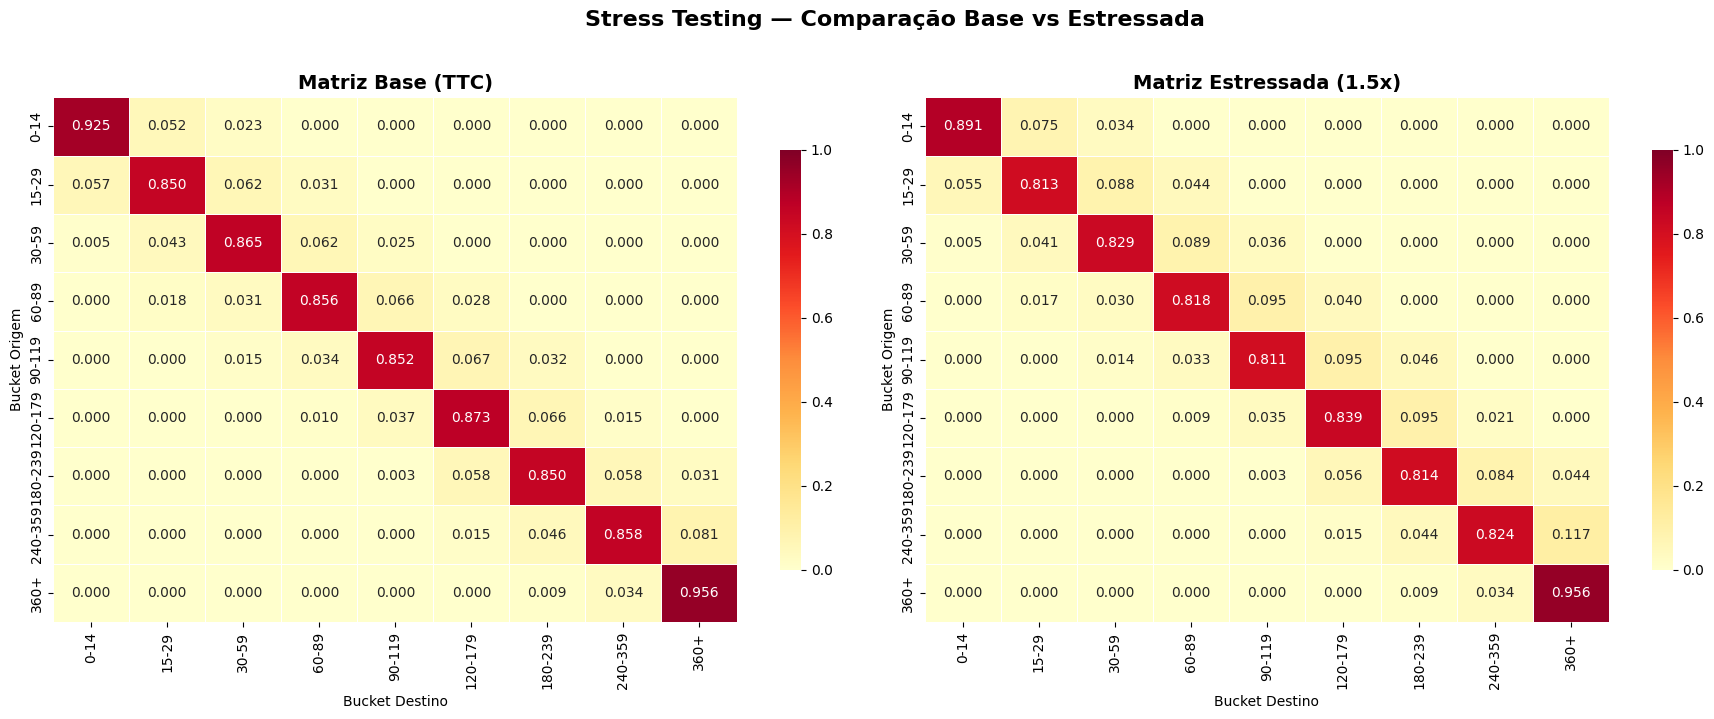

In [24]:
# Comparação visual: Matriz Base vs Estressada
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

base_matrix = learner.transition_matrix_

# Base
sns.heatmap(base_matrix.astype(float), annot=True, fmt='.3f', cmap='YlOrRd',
            ax=axes[0], vmin=0, vmax=1, linewidths=0.5, cbar_kws={'shrink': 0.8})
axes[0].set_title('Matriz Base (TTC)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Bucket Destino')
axes[0].set_ylabel('Bucket Origem')

# Estressada
sns.heatmap(stressed.astype(float), annot=True, fmt='.3f', cmap='YlOrRd',
            ax=axes[1], vmin=0, vmax=1, linewidths=0.5, cbar_kws={'shrink': 0.8})
axes[1].set_title('Matriz Estressada (1.5x)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Bucket Destino')
axes[1].set_ylabel('Bucket Origem')

plt.suptitle('Stress Testing — Comparação Base vs Estressada', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [25]:
# 8.1.3 Gerar cenários (base, otimista, pessimista)
scenarios = generate_scenarios(learner.transition_matrix_, {
    'base':        {'factor': 1.0, 'weight': 0.40},
    'otimista':    {'factor': 0.7, 'weight': 0.30},
    'pessimista':  {'factor': 1.8, 'weight': 0.30}
})

weights = scenarios.pop('_weights')
print("Cenários gerados:", list(scenarios.keys()))
print("Pesos:", weights)

# 8.1.4 Matriz forward-looking ponderada
scenarios['_weights'] = weights
fl_matrix = weighted_scenario_matrix(scenarios)
print("\nMatriz Forward-Looking (ponderada):")
print(fl_matrix.round(4).to_string())

Cenários gerados: ['base', 'otimista', 'pessimista']
Pesos: {'base': 0.4, 'otimista': 0.3, 'pessimista': 0.3}

Matriz Forward-Looking (ponderada):
           0-14   15-29   30-59   60-89  90-119  120-179  180-239  240-359    360+
0-14     0.9152  0.0586  0.0263  0.0000  0.0000   0.0000   0.0000   0.0000  0.0000
15-29    0.0567  0.8400  0.0689  0.0344  0.0000   0.0000   0.0000   0.0000  0.0000
30-59    0.0050  0.0422  0.8555  0.0693  0.0281   0.0000   0.0000   0.0000  0.0000
60-89    0.0000  0.0179  0.0310  0.8459  0.0742   0.0310   0.0000   0.0000  0.0000
90-119   0.0000  0.0000  0.0149  0.0340  0.8407   0.0745   0.0360   0.0000  0.0000
120-179  0.0000  0.0000  0.0000  0.0097  0.0363   0.8635   0.0741   0.0165  0.0000
180-239  0.0000  0.0000  0.0000  0.0000  0.0030   0.0576   0.8397   0.0653  0.0344
240-359  0.0000  0.0000  0.0000  0.0000  0.0000   0.0151   0.0452   0.8486  0.0912
360+     0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0094   0.0344  0.9562


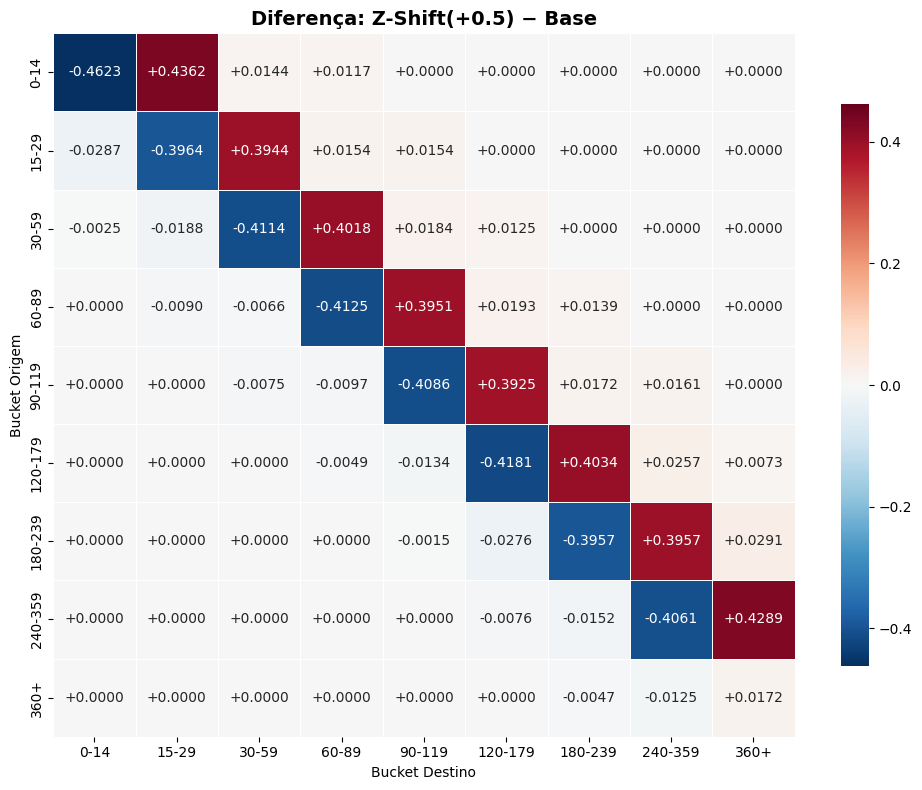

In [26]:
# Mapa de diferença: Z-Shift vs Base
fig, ax = plt.subplots(figsize=(10, 8))

diff = shifted.astype(float) - base_matrix.astype(float)
max_abs = max(abs(diff.values.min()), abs(diff.values.max()))

sns.heatmap(diff, annot=True, fmt='+.4f', cmap='RdBu_r',
            center=0, vmin=-max_abs, vmax=max_abs,
            linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Diferença: Z-Shift(+0.5) − Base', fontsize=14, fontweight='bold')
ax.set_xlabel('Bucket Destino')
ax.set_ylabel('Bucket Origem')
plt.tight_layout()
plt.show()

### 8.2 Staging IFRS 9

Classifique contratos em **Stage 1** (performing, 12-month PD), **Stage 2** (underperforming, lifetime PD) e **Stage 3** (default, PD = 100%).

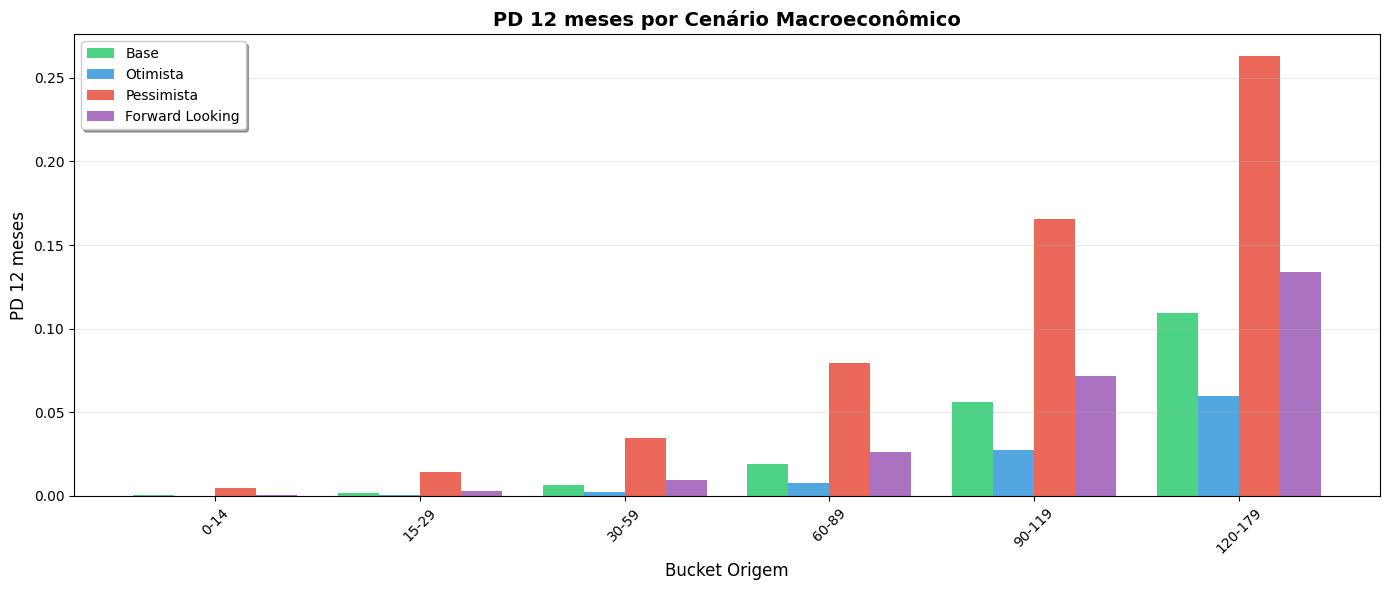

In [27]:
# Comparação de PD por cenário
from credit_risk_transition_matrix.core.pd_engine import cumulative_pd

default_states = [base_matrix.columns[-1]]  # ultimo bucket = default

# PD 12m para cada cenário
scenario_pds = {}
for name, mat in scenarios.items():
    if name == '_weights':
        continue
    cpd = cumulative_pd(mat, n_periods=12, default_states=default_states)
    scenario_pds[name] = cpd.iloc[-1].to_dict()  # PD at period 12

# Forward-looking
cpd_fl = cumulative_pd(fl_matrix, n_periods=12, default_states=default_states)
scenario_pds['forward_looking'] = cpd_fl.iloc[-1].to_dict()

# Plot
buckets_to_show = list(base_matrix.index)[:6]  # buckets não-default
n_buckets = len(buckets_to_show)
n_scenarios = len(scenario_pds)

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(n_buckets)
width = 0.8 / n_scenarios

colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6']
for i, (name, pds) in enumerate(scenario_pds.items()):
    vals = [pds.get(b, 0) for b in buckets_to_show]
    ax.bar(x + i * width, vals, width, label=name.replace('_', ' ').title(), color=colors[i % len(colors)], alpha=0.85)

ax.set_xlabel('Bucket Origem', fontsize=12)
ax.set_ylabel('PD 12 meses', fontsize=12)
ax.set_title('PD 12 meses por Cenário Macroeconômico', fontsize=14, fontweight='bold')
ax.set_xticks(x + width * (n_scenarios - 1) / 2)
ax.set_xticklabels(buckets_to_show, rotation=45)
ax.legend(frameon=True, fancybox=True, shadow=True)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
from credit_risk_transition_matrix import classify_stage, stage_migration_matrix, stage_summary

# Criar snapshot mais recente de cada contrato para classificação
snapshot = df.sort_values('data_ref').groupby('id_contrato').last().reset_index()

# Atribuir bucket label ao snapshot
bucket_boundaries = [0, 15, 30, 60, 90, 120, 180, 240, 360]
import numpy as np
snapshot['bucket'] = pd.cut(
    snapshot['dias_atraso'],
    bins=bucket_boundaries + [np.inf],
    labels=learner.bucket_labels_,
    right=False
).astype(str)

print(f"Snapshot: {len(snapshot)} contratos")
print(f"Buckets: {learner.bucket_labels_}")
print(f"Distribuição:")
print(snapshot['bucket'].value_counts().sort_index())

Snapshot: 500 contratos
Buckets: ['0-14', '15-29', '30-59', '60-89', '90-119', '120-179', '180-239', '240-359', '360+']
Distribuição:
bucket
0-14       118
120-179     42
15-29       81
180-239     26
240-359     18
30-59       79
360+        25
60-89       63
90-119      48
Name: count, dtype: int64


In [29]:
# 8.2.1 Classificar stages
df_staged = classify_stage(
    snapshot,
    bucket_col='bucket',
    bucket_labels=learner.bucket_labels_,
    stage1_max_bucket='15-29',
    default_buckets=['360+']
)

print("Distribuição por Stage:")
print(df_staged['stage'].value_counts().sort_index())
print()

# 8.2.2 Resumo por Stage
resumo = stage_summary(df_staged, stage_col='stage', ead_col='ead')
print("Resumo por Stage:")
resumo

Distribuição por Stage:
stage
1    199
2    276
3     25
Name: count, dtype: int64

Resumo por Stage:


,stage,count,pct_count,ead_total,ead_mean,pct_ead
0,Stage 1,199,0.398,14329787.35,72008.981658,0.274032
1,Stage 2,276,0.552,34350485.16,124458.279565,0.656893
2,Stage 3,25,0.050,3612094.36,144483.774400,0.069075


In [30]:
# 8.2.3 Matriz de migração entre stages
# (precisa da série temporal completa com stages)

# Primeiro, classificar toda a série temporal
df_full = df.copy()
df_full['bucket'] = pd.cut(
    df_full['dias_atraso'],
    bins=bucket_boundaries + [np.inf],
    labels=learner.bucket_labels_,
    right=False
).astype(str)

df_full_staged = classify_stage(
    df_full,
    bucket_col='bucket',
    bucket_labels=learner.bucket_labels_,
    stage1_max_bucket='15-29',
    default_buckets=['360+']
)

migration = stage_migration_matrix(
    df_full_staged,
    id_col='id_contrato',
    time_col='data_ref',
    stage_col='stage'
)

print("Matriz de Migração entre Stages:")
print(migration.round(4).to_string())

Matriz de Migração entre Stages:
         Stage 1  Stage 2  Stage 3
Stage 1   0.9560   0.0440   0.0000
Stage 2   0.0209   0.9722   0.0069
Stage 3   0.0000   0.0477   0.9523


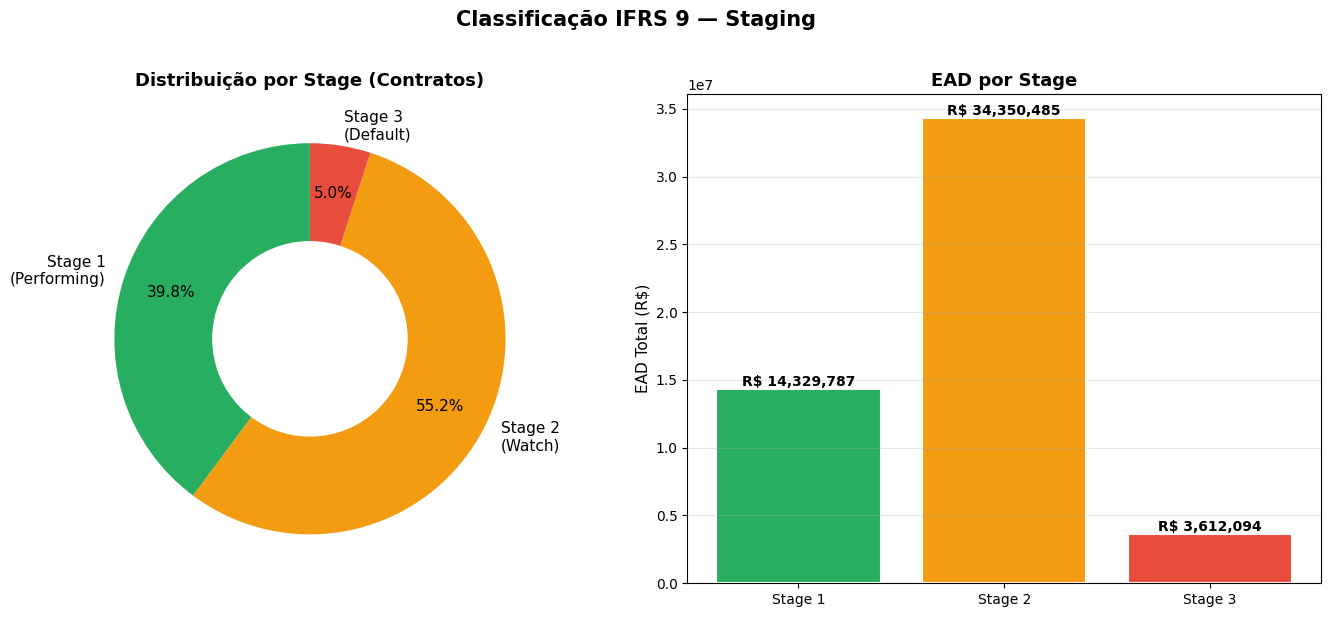

In [31]:
# Distribuição por Stage — Gráfico de Rosca + Barras
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

stage_counts = df_staged['stage'].value_counts().sort_index()
stage_names = ['Stage 1\n(Performing)', 'Stage 2\n(Watch)', 'Stage 3\n(Default)']
colors_stage = ['#27ae60', '#f39c12', '#e74c3c']

# Donut chart
wedges, texts, autotexts = axes[0].pie(
    stage_counts.values,
    labels=stage_names[:len(stage_counts)],
    colors=colors_stage[:len(stage_counts)],
    autopct='%1.1f%%',
    pctdistance=0.75,
    startangle=90,
    textprops={'fontsize': 11}
)
centre_circle = plt.Circle((0, 0), 0.50, fc='white')
axes[0].add_artist(centre_circle)
axes[0].set_title('Distribuição por Stage (Contratos)', fontsize=13, fontweight='bold')

# Bar chart with EAD
if 'ead' in df_staged.columns:
    ead_by_stage = df_staged.groupby('stage')['ead'].sum()
    bars = axes[1].bar(
        [f'Stage {s}' for s in ead_by_stage.index],
        ead_by_stage.values,
        color=colors_stage[:len(ead_by_stage)],
        edgecolor='white', linewidth=1.5
    )
    axes[1].set_title('EAD por Stage', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('EAD Total (R$)', fontsize=11)
    axes[1].grid(axis='y', alpha=0.3)
    # Valores acima das barras
    for bar, val in zip(bars, ead_by_stage.values):
        axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                     f'R$ {val:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Classificação IFRS 9 — Staging', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 8.3 ECL — Expected Credit Loss

Calcule a **Perda Esperada** (ECL) por contrato com PD adequada ao estágio:
- Stage 1: PD 12 meses × LGD × EAD
- Stage 2: PD lifetime × LGD × EAD
- Stage 3: 100% × LGD × EAD

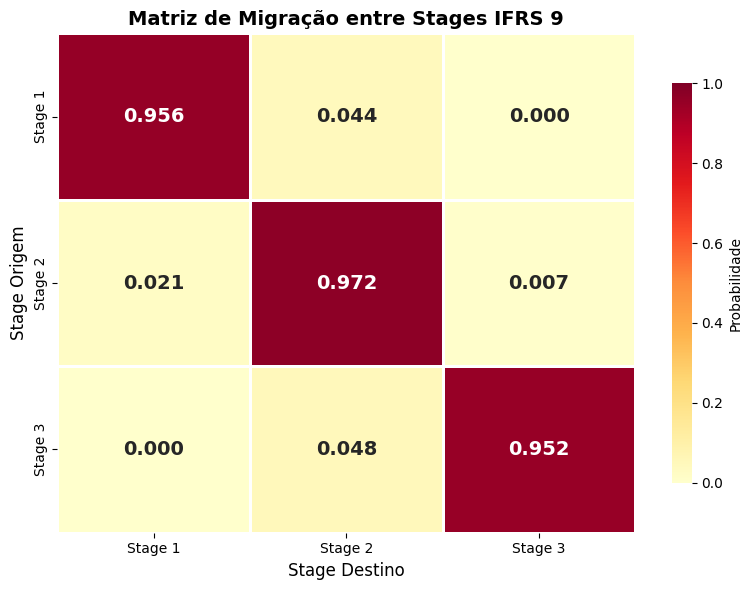

In [32]:
# Heatmap da matriz de migração entre stages
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(migration.astype(float), annot=True, fmt='.3f', cmap='YlOrRd',
            vmin=0, vmax=1, linewidths=2, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'Probabilidade'},
            annot_kws={'fontsize': 14, 'fontweight': 'bold'})
ax.set_title('Matriz de Migração entre Stages IFRS 9', fontsize=14, fontweight='bold')
ax.set_xlabel('Stage Destino', fontsize=12)
ax.set_ylabel('Stage Origem', fontsize=12)
plt.tight_layout()
plt.show()

In [33]:
from credit_risk_transition_matrix import ecl_by_stage, portfolio_ecl

# 8.3.1 ECL por contrato
df_ecl = ecl_by_stage(
    transition_matrix=learner.transition_matrix_,
    df=df_staged,
    bucket_col='bucket',
    stage_col='stage',
    ead_col='ead',
    lgd=0.45,
    n_periods_12m=12,
    n_periods_lifetime=60
)

print(f"ECL Total: R$ {df_ecl['ecl'].sum():,.2f}")
print(f"EAD Total: R$ {df_ecl['ead'].sum():,.2f}")
print(f"Coverage Ratio: {df_ecl['ecl'].sum() / df_ecl['ead'].sum() * 100:.4f}%")
print()
print("Primeiros registros com ECL:")
df_ecl[['id_contrato', 'bucket', 'stage', 'ead', 'pd_used', 'lgd_used', 'ecl']].head(10)

ECL Total: R$ 6,591,300.88
EAD Total: R$ 52,292,366.87
Coverage Ratio: 12.6047%

Primeiros registros com ECL:


,id_contrato,bucket,stage,ead,pd_used,lgd_used,ecl
0,CTR-0001,120-179,2,95317.86,0.376121,0.45,16132.964468
1,CTR-0002,30-59,2,62716.76,0.211317,0.45,5963.910792
2,CTR-0003,0-14,1,7778.31,0.000477,0.45,1.670240
3,CTR-0004,90-119,2,302574.74,0.328370,0.45,44710.431725
4,CTR-0005,30-59,2,15454.93,0.211317,0.45,1469.652192
5,CTR-0006,30-59,2,98636.79,0.211317,0.45,9379.646149
6,CTR-0007,30-59,2,5900.89,0.211317,0.45,561.132009
7,CTR-0008,60-89,2,150921.19,0.267830,0.45,18189.555976
8,CTR-0009,15-29,1,18382.42,0.001987,0.45,16.439863
9,CTR-0010,0-14,1,16392.15,0.000477,0.45,3.519893


In [34]:
# 8.3.2 Resumo ECL do portfólio por Stage
resumo_ecl = portfolio_ecl(df_ecl, stage_col='stage', ead_col='ead', ecl_col='ecl')
print("ECL por Stage:")
resumo_ecl

ECL por Stage:


,stage,count,ead_total,ecl_total,pd_mean,coverage_ratio
0,Stage 1,199,14329787.35,8.527625e+03,0.001092,0.000595
1,Stage 2,276,34350485.16,4.957331e+06,0.305604,0.144316
2,Stage 3,25,3612094.36,1.625442e+06,1.000000,0.450000
3,Total,500,52292366.87,6.591301e+06,0.219128,0.126047


In [35]:
# 8.3.3 Resumo ECL por Stage e Segmento
resumo_seg = portfolio_ecl(
    df_ecl, 
    stage_col='stage', 
    ead_col='ead', 
    ecl_col='ecl',
    segment_col='segmento'
)
print("ECL por Stage × Segmento:")
resumo_seg

ECL por Stage × Segmento:


,segmento,stage,count,ead_total,ecl_total,pd_mean,coverage_ratio
0,Consignado,Stage 1,61,656956.17,2.240262e+02,0.000700,0.000341
1,Consignado,Stage 2,32,304095.42,3.859740e+04,0.284857,0.126925
2,Consignado,Stage 3,1,7517.51,3.382880e+03,1.000000,0.450000
3,Pessoa Física,Stage 1,104,4892104.90,2.685997e+03,0.001203,0.000549
4,Pessoa Física,Stage 2,148,8017632.11,1.064475e+06,0.298010,0.132767
5,Pessoa Física,Stage 3,12,806850.58,3.630828e+05,1.000000,0.450000
6,Pessoa Jurídica,Stage 1,34,8780726.28,5.617602e+03,0.001454,0.000640
7,Pessoa Jurídica,Stage 2,96,26028757.63,3.854258e+06,0.324225,0.148077
8,Pessoa Jurídica,Stage 3,12,2797726.27,1.258977e+06,1.000000,0.450000
9,ALL,Total,500,52292366.87,6.591301e+06,0.219128,0.126047


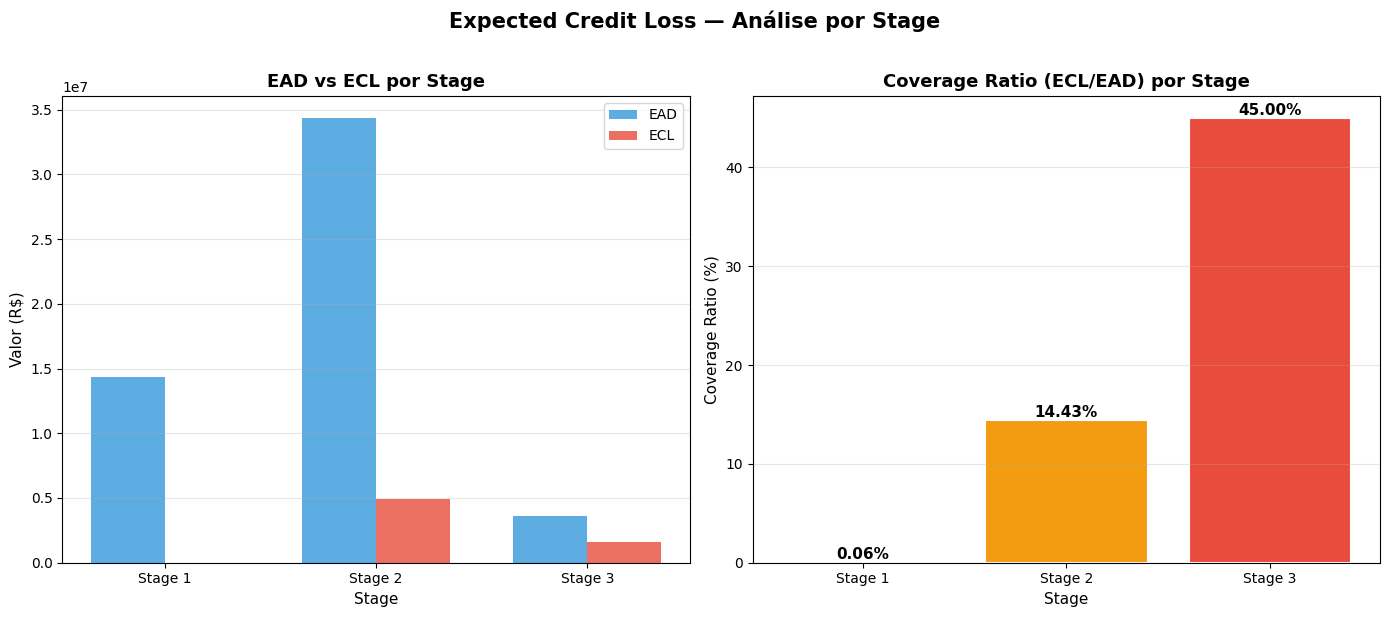

In [36]:
# ECL por Stage — Barras empilhadas e Coverage Ratio
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Filtrar apenas stages (não total)
ecl_stages = resumo_ecl[resumo_ecl['stage'] != 'Total'].copy()
colors_ecl = ['#27ae60', '#f39c12', '#e74c3c']

# Bar chart: EAD vs ECL por Stage
x_pos = np.arange(len(ecl_stages))
bar_width = 0.35

bars1 = axes[0].bar(x_pos - bar_width/2, ecl_stages['ead_total'], bar_width,
                     label='EAD', color='#3498db', alpha=0.8)
bars2 = axes[0].bar(x_pos + bar_width/2, ecl_stages['ecl_total'], bar_width,
                     label='ECL', color='#e74c3c', alpha=0.8)

axes[0].set_xlabel('Stage', fontsize=11)
axes[0].set_ylabel('Valor (R$)', fontsize=11)
axes[0].set_title('EAD vs ECL por Stage', fontsize=13, fontweight='bold')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(ecl_stages['stage'].tolist())
axes[0].legend(frameon=True, fancybox=True)
axes[0].grid(axis='y', alpha=0.3)

# Coverage ratio por Stage
bars3 = axes[1].bar(x_pos, ecl_stages['coverage_ratio'] * 100,
                     color=colors_ecl[:len(ecl_stages)], edgecolor='white', linewidth=1.5)
axes[1].set_xlabel('Stage', fontsize=11)
axes[1].set_ylabel('Coverage Ratio (%)', fontsize=11)
axes[1].set_title('Coverage Ratio (ECL/EAD) por Stage', fontsize=13, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(ecl_stages['stage'].tolist())
axes[1].grid(axis='y', alpha=0.3)
for bar, val in zip(bars3, ecl_stages['coverage_ratio'] * 100):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                 f'{val:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle('Expected Credit Loss — Análise por Stage', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [37]:
# 8.3.4 ECL com matriz forward-looking (cenários ponderados)
df_ecl_fl = ecl_by_stage(
    transition_matrix=fl_matrix,  # usa a matriz forward-looking
    df=df_staged,
    bucket_col='bucket',
    stage_col='stage',
    ead_col='ead',
    lgd=0.45
)

resumo_fl = portfolio_ecl(df_ecl_fl)

print("Comparação ECL Base vs Forward-Looking:")
print(f"  ECL Base:            R$ {df_ecl['ecl'].sum():,.2f}")
print(f"  ECL Forward-Looking: R$ {df_ecl_fl['ecl'].sum():,.2f}")
print(f"  Diferença:           R$ {df_ecl_fl['ecl'].sum() - df_ecl['ecl'].sum():,.2f}")
print(f"  Impacto:             {(df_ecl_fl['ecl'].sum() / df_ecl['ecl'].sum() - 1) * 100:+.2f}%")

Comparação ECL Base vs Forward-Looking:
  ECL Base:            R$ 6,591,300.88
  ECL Forward-Looking: R$ 7,505,678.06
  Diferença:           R$ 914,377.18
  Impacto:             +13.87%


---

**Fim do notebook demonstrativo.** 

Para uso em Databricks, instale com `pip install -e .` no cluster e use `learner.log_to_mlflow()` para tracking. Visualizações Plotly podem ser usadas com `from credit_risk_transition_matrix.visualization.plotly_charts import plot_heatmap_plotly`.

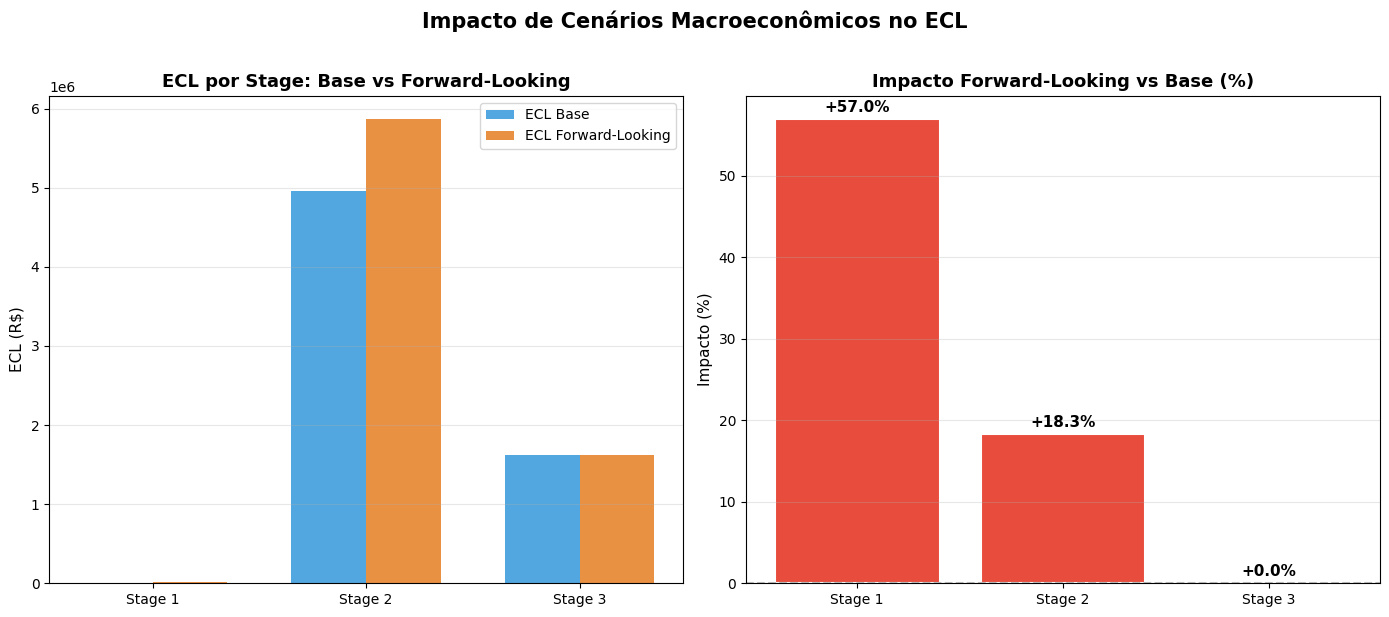

In [38]:
# Comparação visual: ECL Base vs Forward-Looking por Stage
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ECL por stage: base vs forward-looking
ecl_base_by_stage = df_ecl.groupby('stage')['ecl'].sum()
ecl_fl_by_stage = df_ecl_fl.groupby('stage')['ecl'].sum()

stage_labels = [f'Stage {s}' for s in sorted(ecl_base_by_stage.index)]
x_pos = np.arange(len(stage_labels))
bar_w = 0.35

axes[0].bar(x_pos - bar_w/2, ecl_base_by_stage.values, bar_w,
            label='ECL Base', color='#3498db', alpha=0.85)
axes[0].bar(x_pos + bar_w/2, ecl_fl_by_stage.values, bar_w,
            label='ECL Forward-Looking', color='#e67e22', alpha=0.85)
axes[0].set_ylabel('ECL (R$)', fontsize=11)
axes[0].set_title('ECL por Stage: Base vs Forward-Looking', fontsize=13, fontweight='bold')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(stage_labels)
axes[0].legend(frameon=True, fancybox=True)
axes[0].grid(axis='y', alpha=0.3)

# Impacto percentual
impact_pct = ((ecl_fl_by_stage - ecl_base_by_stage) / ecl_base_by_stage * 100).fillna(0)
colors_impact = ['#e74c3c' if v > 0 else '#27ae60' for v in impact_pct.values]
bars = axes[1].bar(x_pos, impact_pct.values, color=colors_impact, edgecolor='white', linewidth=1.5)
axes[1].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
axes[1].set_ylabel('Impacto (%)', fontsize=11)
axes[1].set_title('Impacto Forward-Looking vs Base (%)', fontsize=13, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(stage_labels)
axes[1].grid(axis='y', alpha=0.3)
for bar, val in zip(bars, impact_pct.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + (0.5 if val >= 0 else -1.5),
                 f'{val:+.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle('Impacto de Cenários Macroeconômicos no ECL', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()